In [51]:
# Importación de las librerías 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [52]:
# Carga de los datos
url = './dataset/3.1.6 diamonds.csv'
df = pd.read_csv(url,sep=',')

In [53]:
df.head()

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


Realizar Exploración Inicial
* Conocer cantidad de observaciones
* Tipo de datos
* Obtener medidas estadísticas (Todas por separado según tipo)
* Revisar valores nulos
* Conocer correlación de todas las características

In [54]:
# Observaciones y características
df.shape

(53940, 11)

In [55]:
# Observaciones
df.shape[0]

53940

In [56]:
# Características
df.shape[1]

11

In [57]:
# Tipos de datos
df.dtypes

Unnamed: 0      int64
carat         float64
cut            object
color          object
clarity        object
depth         float64
table         float64
price           int64
x             float64
y             float64
z             float64
dtype: object

In [58]:
# Medidas estadísticas de características cunatitativas
df.describe()

,Unnamed: 0,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,26970.500000,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,15571.281097,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,1.000000,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,13485.750000,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,26970.500000,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,40455.250000,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,53940.000000,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [59]:
# Medidas estadísticas de características cunatitativas
df.describe(include = 'object')

,cut,color,clarity
count,53940,53940,53940
unique,5,7,8
top,Ideal,G,SI1
freq,21551,11292,13065


In [60]:
# Verificar la cantidad de nulos
df.isnull().sum()

Unnamed: 0    0
carat         0
cut           0
color         0
clarity       0
depth         0
table         0
price         0
x             0
y             0
z             0
dtype: int64

In [61]:
for x in df.columns:
    print('La cantidad de valores nulos en la columna', x, 'es de',df[x].isna().sum())

La cantidad de valores nulos en la columna Unnamed: 0 es de 0
La cantidad de valores nulos en la columna carat es de 0
La cantidad de valores nulos en la columna cut es de 0
La cantidad de valores nulos en la columna color es de 0
La cantidad de valores nulos en la columna clarity es de 0
La cantidad de valores nulos en la columna depth es de 0
La cantidad de valores nulos en la columna table es de 0
La cantidad de valores nulos en la columna price es de 0
La cantidad de valores nulos en la columna x es de 0
La cantidad de valores nulos en la columna y es de 0
La cantidad de valores nulos en la columna z es de 0


In [62]:
# Correlación
df.corr()

,Unnamed: 0,carat,depth,table,price,x,y,z
Unnamed: 0,1.000000,-0.377983,-0.034800,-0.100830,-0.306873,-0.405440,-0.395843,-0.399208
carat,-0.377983,1.000000,0.028224,0.181618,0.921591,0.975094,0.951722,0.953387
depth,-0.034800,0.028224,1.000000,-0.295779,-0.010647,-0.025289,-0.029341,0.094924
table,-0.100830,0.181618,-0.295779,1.000000,0.127134,0.195344,0.183760,0.150929
price,-0.306873,0.921591,-0.010647,0.127134,1.000000,0.884435,0.865421,0.861249
x,-0.405440,0.975094,-0.025289,0.195344,0.884435,1.000000,0.974701,0.970772
y,-0.395843,0.951722,-0.029341,0.183760,0.865421,0.974701,1.000000,0.952006
z,-0.399208,0.953387,0.094924,0.150929,0.861249,0.970772,0.952006,1.000000


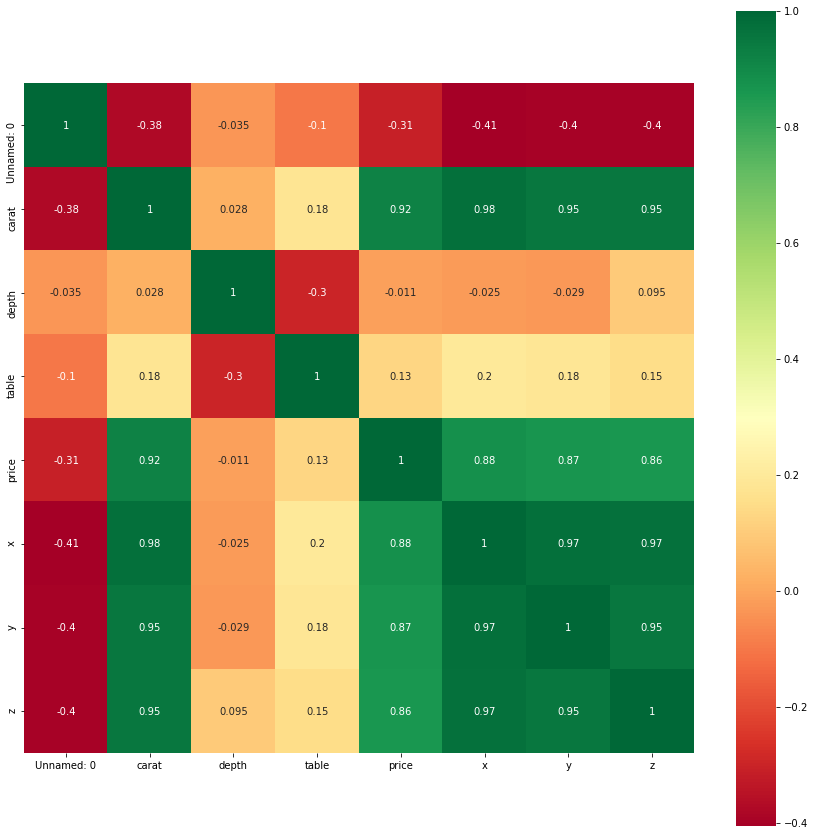

In [63]:
# Analizar la correlación de variables
import seaborn as sns
plt.figure(figsize = (15,15))
p = sns.heatmap(df.corr(),annot = True, cmap = 'RdYlGn',square=True)

In [64]:
# Podemos ver las mejores correlaciones para poder gráficar con el mapa de calor

Analizando el gráfico
* ¿Qué Columna posee la mayor correlación que no involucre a x, y, z?
* r: *Carac* con *price* con un 92%
* x, y , z poseen una alta correlación con precio

C:\ProgramData\Anaconda3\lib\site-packages\seaborn\distributions.py:2551: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


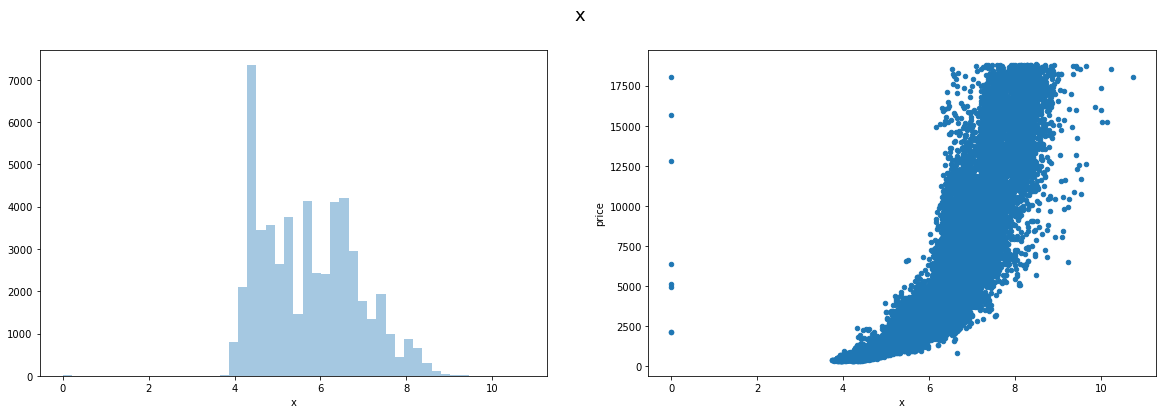

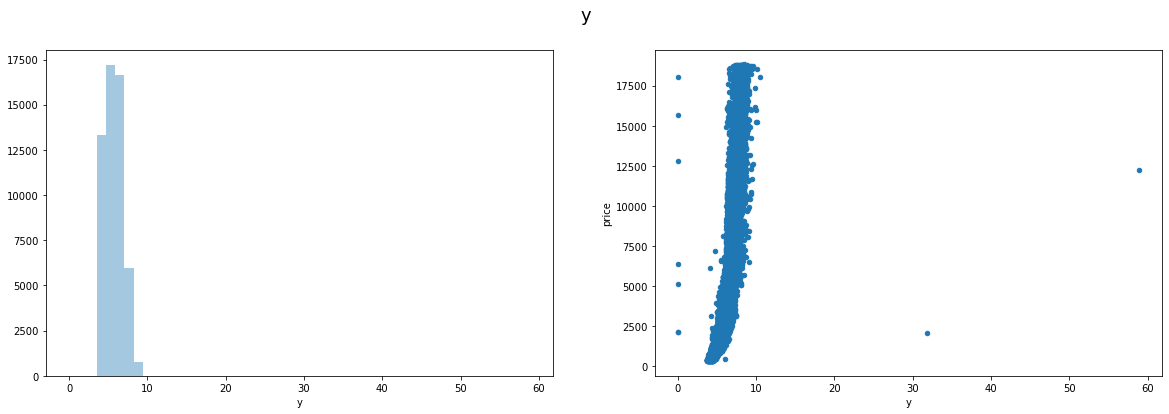

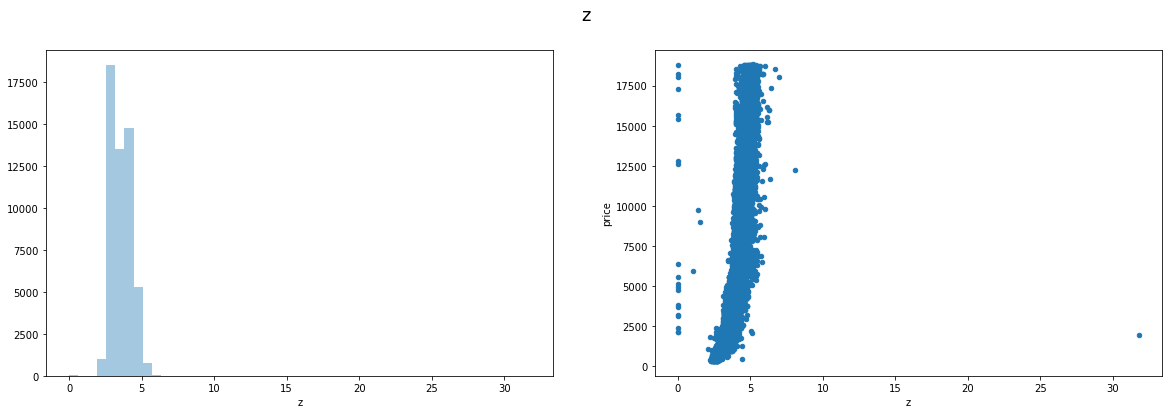

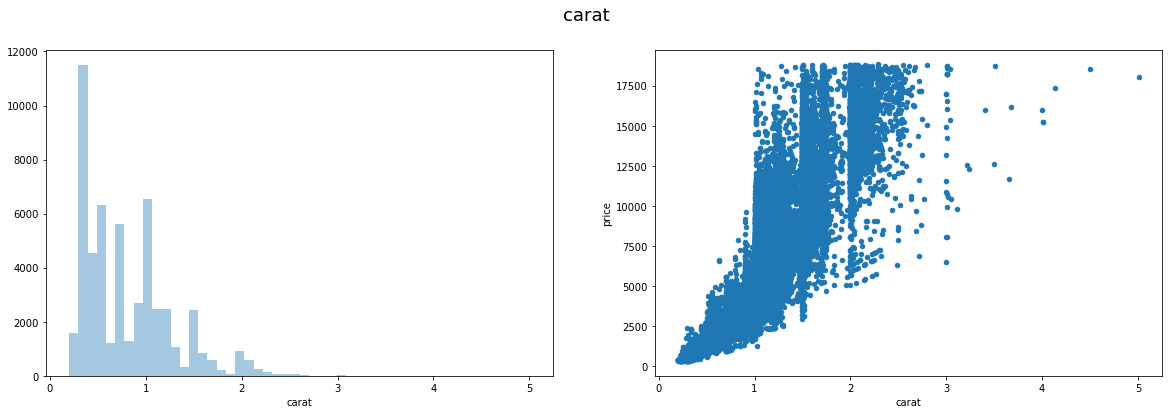

In [65]:
for col in ['x','y','z','carat']:
    fig, ax = plt.subplots(1,2,figsize = (20,6))
    fig.suptitle(col,fontsize = 18)
    sns.distplot(df[col], ax = ax[0], kde = False)
    df[[col] + ['price']].plot.scatter(x = col, y = 'price', ax = ax[1])
    plt.show

In [66]:
df = df.drop(['Unnamed: 0'], axis = 1)

In [67]:
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [68]:
df.shape

(53940, 10)

In [69]:
# Borramos los diamantes que pesan 0 quilates
df = df[[(df[['x','y','z']] != 0)].all(axis = 1)]

AttributeError: 'list' object has no attribute 'all'

In [ ]:
for col in ['x','y','z','carat']:
    fig, ax = plt.subplots(1,2,figsize = (20,6))
    fig.suptitle(col,fontsize = 18)
    sns.displot(df[col], ax = ax[0], kde = False)
    df[[col] + ['price']].plot.scatter(x = col, y = 'price', ax = ax[1])
    plt.show

In [28]:
df['cut'].unique()

array(['Ideal', 'Premium', 'Good', 'Very Good', 'Fair'], dtype=object)

In [29]:
df['color'].unique()

array(['E', 'I', 'J', 'H', 'F', 'G', 'D'], dtype=object)

In [30]:
df['clarity'].unique()

array(['SI2', 'SI1', 'VS1', 'VS2', 'VVS2', 'VVS1', 'I1', 'IF'],
      dtype=object)

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
ct = ColumnTransformer(transformers=[('encoder', OneHotEncoder(),['cut'])],remainder='passthrough')
X = np.array(ct.fit_transform(df))
df2 = pd.DataFrame(X)
df2.head(3)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,0,0,1,0,0,0.23,E,SI2,61.5,55,326,3.95,3.98,2.43
1,0,0,0,1,0,0.21,E,SI1,59.8,61,326,3.89,3.84,2.31
2,0,1,0,0,0,0.23,E,VS1,56.9,65,327,4.05,4.07,2.31


In [41]:
df2.shape

(53940, 14)

In [34]:
ct = ColumnTransformer(transformers=[('encoder', OneHotEncoder(),['color'])],remainder='passthrough')
X = np.array(ct.fit_transform(df))
df3 = pd.DataFrame(X)
df3.head(3)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,0,1,0,0,0,0,0,0.23,Ideal,SI2,61.5,55,326,3.95,3.98,2.43
1,0,1,0,0,0,0,0,0.21,Premium,SI1,59.8,61,326,3.89,3.84,2.31
2,0,1,0,0,0,0,0,0.23,Good,VS1,56.9,65,327,4.05,4.07,2.31


In [35]:
df3.shape

(53940, 16)

In [36]:
ct = ColumnTransformer(transformers=[('encoder', OneHotEncoder(),['clarity'])],remainder='passthrough')
X = np.array(ct.fit_transform(df))
df4 = pd.DataFrame(X)
df4.head(3)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
0,0,0,0,1,0,0,0,0,0.23,Ideal,E,61.5,55,326,3.95,3.98,2.43
1,0,0,1,0,0,0,0,0,0.21,Premium,E,59.8,61,326,3.89,3.84,2.31
2,0,0,0,0,1,0,0,0,0.23,Good,E,56.9,65,327,4.05,4.07,2.31


In [40]:
df4.shape

(53940, 17)

In [43]:
# 
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Se separan las variables predictoras y predecida
x = df[['x','y','z','carat']] # Variables independientes
y = df['price'] # Variable dependiente

# Realizar separación de entrenamiento 
X_train, X_test, y_train, y_test = train_test_split(x,y,test_size = 0.2, random_state = 29)

# Indicar tipo de modelo
modelo = LinearRegression()

# Entrenar el modelo 
modelo.fit(X_train, y_train)

# Validar el modelo
y_predic = modelo.predict(X_test)

#
print(y_predic)

# Evaluación del modelo
print('R2 : %.2f' % r2_score(y_test,y_predic))

print("Mse: %.2f" % mean_squared_error(y_predic,y_test))

print("Score del modelo : %.2f" % modelo.score(X_train,y_train))

[ 647.30696496 7550.9075244  5401.36637052 ... 1000.55110485 1005.49493746
  934.42524849]
R2 : 0.85
Mse: 2315259.85
Score del modelo : 0.85


In [44]:
X_test.head()

,x,y,z,carat
18043,4.53,4.59,2.79,0.35
14590,6.96,6.99,4.28,1.28
12722,6.50,6.47,3.97,1.02
5432,5.90,5.97,3.69,0.79
11950,6.46,6.51,4.01,1.01


In [46]:
# Predicción entregando los valores que tenemos el entrenamiento
y_predic = modelo.predict([[4.53,4.59,2.79,0.35]])
y_predic

array([647.30696496])

In [47]:
# Predicción con valores propios
y_predic = modelo.predict([[4,4,2,1]])
y_predic

array([7995.80663854])